# Estimativa de idade por imagem para evitar a venda de álcool a menores (versão corrigida)

# Contents <a id='back'></a>

* [Introdução](#intro)
* [Etapa 1. Preparando o ambiente e os dados](#data)
* [Etapa 2. Análise exploratória](#eda)
* [Etapa 3. Pipeline de imagens](#pipeline)
* [Etapa 4. Modelo](#model)
* [Etapa 5. Treinamento](#training)
* [Etapa 6. Avaliação no conjunto de teste](#evaluation)
* [Etapa 7. Uso no negócio: quando pedir documento](#business)
* [Conclusão geral](#end)

## Introdução <a id='intro'></a>

Estabelecimentos comerciais precisam verificar a idade dos clientes na venda de bebidas alcoólicas. A proposta é um modelo de visão computacional que estime a idade de uma pessoa a partir de uma foto do rosto, apoiando essa verificação no momento da compra.

### Por que uma versão corrigida
A primeira versão deste projeto alcançou erro médio (MAE) de 5,79 anos na validação, mas tinha três pontos de melhoria:

1. A camada de saída tinha **12 neurônios** (`Dense(12)`), quando o correto, para prever um único número (a idade), é **1 neurônio** (`Dense(1)`).
2. O modelo foi avaliado só na **validação**, que também foi usada para acompanhar o treino. Aqui, uso um **conjunto de teste** separado, que o modelo só vê no final.
3. Havia **overfitting**: erro de 2,1 anos no treino contra 5,8 na validação. Aqui, uso mais aumento de dados, *dropout* e *early stopping*.

Também uso o **pré-processamento oficial da ResNet50** (`preprocess_input`), que é o formato em que ela foi treinada no ImageNet, em vez de apenas dividir os pixels por 255.

### Dados
**7.591 fotos de rostos** com a idade real de cada pessoa, o mesmo conjunto usado na primeira versão do projeto. As fotos são um subconjunto da base pública de pesquisa **APPA-REAL** e já vêm recortadas no rosto.

Como o servidor oficial da APPA-REAL está fora do ar, o notebook baixa as fotos de uma cópia pública no GitHub, usada para fins de estudo. As imagens não são redistribuídas neste repositório.

Fonte original: Agustsson, E., Timofte, R., Escalera, S., Baró, X., Guyon, I., & Rothe, R. (2017). *Apparent and real age estimation in still images with deep residual regressors on APPA-REAL database*. ChaLearn LAP. Uso exclusivo para pesquisa e estudo.

### Como executar no Google Colab
1. **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)**
2. **Ambiente de execução → Executar tudo**

O download dos dados e o treinamento levam, juntos, cerca de 20 a 40 minutos.

[Voltar ao Índice](#back)

## Etapa 1. Preparando o ambiente e os dados <a id='data'></a>

In [1]:
# Importa as bibliotecas necessárias
import os  # Utilizada para navegar pelas pastas
import urllib.request  # Utilizada para baixar os dados
import zipfile  # Utilizada para descompactar os dados

import numpy as np  # Utilizada para operações numéricas
import pandas as pd  # Utilizada para manipulação de dados
import matplotlib.pyplot as plt  # Utilizada para a construção de gráficos
import tensorflow as tf  # Biblioteca de deep learning
from tensorflow import keras  # API de alto nível do TensorFlow
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input  # Rede pré-treinada

SEMENTE = 42
tf.random.set_seed(SEMENTE)
np.random.seed(SEMENTE)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, LARANJA, CINZA, VERMELHO = "#1f4e79", "#e07b00", "#9aa5b1", "#c0392b"

# Confirma que a GPU está ativa: sem ela, o treinamento leva horas
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponível:", gpus if gpus else "NENHUMA. Ative em Ambiente de execução → Alterar o tipo de ambiente.")
print("TensorFlow", tf.__version__)

GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow 2.21.0


In [2]:
# Baixa as fotos e o arquivo de idades (somente na primeira execução)
# Cópias públicas do mesmo conjunto de fotos; se a primeira falhar, usa a segunda
FONTES = [
    ("https://github.com/mnunezsa95/ds_project_neural_network.git", "ds_project_neural_network/data"),
    ("https://github.com/santicar1809/neural_networks.git", "neural_networks/faces"),
]

PASTA = None
for url, pasta in FONTES:
    if not os.path.exists(pasta):
        print(f"Baixando as fotos de {url} (cerca de 250 MB)...")
        os.system(f"git clone --depth 1 --quiet {url}")
    if os.path.exists(os.path.join(pasta, "labels.csv")):
        PASTA = pasta
        break

assert PASTA is not None, "Não foi possível baixar as fotos. Verifique a conexão e rode a célula de novo."
print("Pasta dos dados:", PASTA)
print("Fotos:", len(os.listdir(os.path.join(PASTA, "final_files"))))

Baixando as fotos de https://github.com/mnunezsa95/ds_project_neural_network.git (cerca de 250 MB)...
Pasta dos dados: ds_project_neural_network/data
Fotos: 7591


O arquivo `labels.csv` traz o nome de cada foto e a idade real da pessoa. Divido as fotos em três partes, mantendo a mesma distribuição de idades em cada uma:

- **Treino (70%):** para ajustar o modelo
- **Validação (15%):** para acompanhar o treino e decidir quando parar
- **Teste (15%):** usado **uma única vez**, no final, para a avaliação definitiva

In [3]:
from sklearn.model_selection import train_test_split

dados = pd.read_csv(os.path.join(PASTA, "labels.csv"))
dados["caminho"] = dados["file_name"].apply(lambda nome: os.path.join(PASTA, "final_files", nome))
dados = dados[dados["caminho"].apply(os.path.exists)].reset_index(drop=True)

# Divisão estratificada por faixa de idade: as três partes ficam com distribuições de idade parecidas
faixa = pd.cut(dados["real_age"], [0, 12, 18, 25, 35, 50, 65, 100])
treino_idx, resto_idx = train_test_split(dados.index, test_size=0.3, stratify=faixa, random_state=SEMENTE)
valid_idx, teste_idx = train_test_split(resto_idx, test_size=0.5, stratify=faixa[resto_idx], random_state=SEMENTE)
dados["parte"] = "train"
dados.loc[valid_idx, "parte"] = "valid"
dados.loc[teste_idx, "parte"] = "test"

print(f"Fotos: {len(dados):,}".replace(",", "."))
print(dados["parte"].value_counts().to_string())

Fotos: 7.591
parte
train    5313
valid    1139
test     1139


[Voltar ao Índice](#back)

## Etapa 2. Análise exploratória <a id='eda'></a>

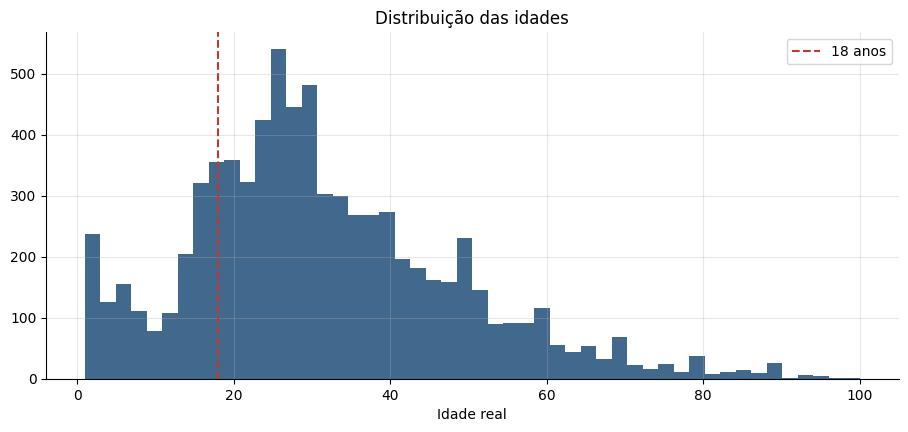

        count  mean   std  min   25%   50%   75%    max
parte                                                  
test   1139.0  31.3  17.1  1.0  20.0  29.0  41.0   96.0
train  5313.0  31.2  17.2  1.0  20.0  28.0  41.0  100.0
valid  1139.0  31.2  16.9  1.0  20.0  29.0  40.0   93.0

Menores de 18 anos: 19.8% das fotos


In [4]:
fig, ax = plt.subplots()
ax.hist(dados["real_age"], bins=50, color=AZUL, alpha=0.85)
ax.axvline(18, color=VERMELHO, ls="--", label="18 anos")
ax.set_title("Distribuição das idades")
ax.set_xlabel("Idade real")
ax.legend()
plt.show()

print(dados.groupby("parte")["real_age"].describe().round(1))
print(f"\nMenores de 18 anos: {(dados['real_age'] < 18).mean():.1%} das fotos")

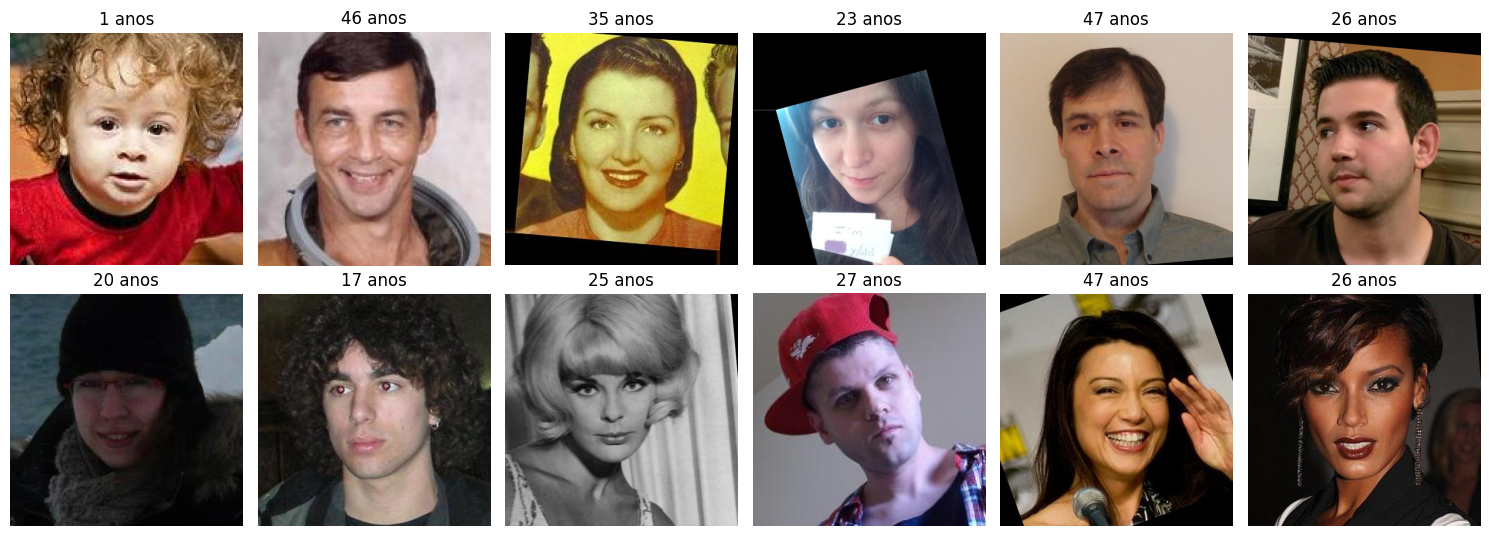

In [5]:
# Amostra de fotos com as idades
amostra = dados.sample(12, random_state=SEMENTE)
fig, axs = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, (_, linha) in zip(axs.flat, amostra.iterrows()):
    ax.imshow(plt.imread(linha["caminho"]))
    ax.set_title(f"{linha['real_age']} anos")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Conclusões

- As idades vão de 1 a 100 anos, com média de 31 e mediana de 29. **19,8% das fotos são de menores de 18 anos**.
- As três partes (treino, validação e teste) têm distribuições de idade praticamente iguais, graças à divisão estratificada.
- As fotos variam em iluminação, ângulo e qualidade, o que torna a tarefa mais difícil e justifica o aumento de dados.

[Voltar ao Índice](#back)

## Etapa 3. Pipeline de imagens <a id='pipeline'></a>

Uso o `tf.data`, que lê e prepara as imagens em paralelo com o treinamento. Cada imagem é redimensionada para 224 x 224 pixels, o tamanho de entrada da ResNet50.

O **aumento de dados** é aplicado só no treino: a cada época, as fotos são espelhadas, giradas, aproximadas e têm o contraste alterado de forma aleatória. Isso faz o modelo ver variações das mesmas pessoas e reduz o overfitting.

In [6]:
TAMANHO = 224
LOTE = 32
AUTOTUNE = tf.data.AUTOTUNE

aumento = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.1),
], name="aumento_de_dados")


def ler_imagem(caminho, idade):
    imagem = tf.io.decode_jpeg(tf.io.read_file(caminho), channels=3)
    imagem = tf.image.resize(imagem, (TAMANHO, TAMANHO))
    return imagem, tf.cast(idade, tf.float32)


def criar_dataset(parte, treino=False):
    df = dados[dados["parte"] == parte]
    ds = tf.data.Dataset.from_tensor_slices((df["caminho"].values, df["real_age"].values))
    if treino:
        ds = ds.shuffle(len(df), seed=SEMENTE)
    ds = ds.map(ler_imagem, num_parallel_calls=AUTOTUNE).batch(LOTE)
    if treino:
        ds = ds.map(lambda x, y: (aumento(x, training=True), y), num_parallel_calls=AUTOTUNE)
    # Pré-processamento oficial da ResNet50
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


ds_treino = criar_dataset("train", treino=True)
ds_validacao = criar_dataset("valid")
ds_teste = criar_dataset("test")
print("Pipelines prontos.")

Pipelines prontos.


[Voltar ao Índice](#back)

## Etapa 4. Modelo <a id='model'></a>

Uso **transfer learning**: a ResNet50 já aprendeu a reconhecer formas, texturas e rostos com milhões de imagens do ImageNet. Aproveito esse conhecimento e ajusto a rede inteira para estimar a idade.

- **Base:** ResNet50 pré-treinada no ImageNet, com *pooling* médio global
- **Dropout de 20%:** desliga neurônios aleatoriamente no treino, contra o overfitting
- **Saída:** `Dense(1)` com ativação ReLU, porque a idade é um único número e nunca é negativa
- **Função de perda:** MAE (erro absoluto médio), que é a própria métrica do projeto
- **Otimizador:** Adam com taxa de aprendizado baixa (0,0001), adequada para ajustar uma rede pré-treinada

In [7]:
def criar_modelo():
    base = ResNet50(weights="imagenet", include_top=False, pooling="avg", input_shape=(TAMANHO, TAMANHO, 3))
    modelo = keras.Sequential([
        base,
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, activation="relu"),  # Correção: 1 neurônio para prever a idade
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), loss="mae", metrics=["mae"])
    return modelo


modelo = criar_modelo()
modelo.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 23,536,641 (89.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

[Voltar ao Índice](#back)

## Etapa 5. Treinamento <a id='training'></a>

Treino por até 30 épocas com dois mecanismos automáticos:

- **Early stopping:** se o erro na validação não melhorar por 5 épocas seguidas, o treino para e o modelo volta para a melhor época
- **Redução da taxa de aprendizado:** se o erro na validação parar de cair por 2 épocas, a taxa de aprendizado é dividida por 5, para ajustes mais finos

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.2, patience=2, min_lr=1e-6),
]
historico = modelo.fit(ds_treino, validation_data=ds_validacao, epochs=30, callbacks=callbacks, verbose=2)

Epoch 1/30
167/167 - 216s - 1s/step - loss: 12.0849 - mae: 12.0849 - val_loss: 11.5361 - val_mae: 11.5361 - learning_rate: 1.0000e-04
Epoch 2/30
167/167 - 89s - 533ms/step - loss: 7.4809 - mae: 7.4809 - val_loss: 9.0281 - val_mae: 9.0281 - learning_rate: 1.0000e-04
Epoch 3/30
167/167 - 88s - 529ms/step - loss: 6.8469 - mae: 6.8469 - val_loss: 8.4178 - val_mae: 8.4178 - learning_rate: 1.0000e-04
Epoch 4/30
167/167 - 89s - 533ms/step - loss: 6.1698 - mae: 6.1698 - val_loss: 10.7314 - val_mae: 10.7314 - learning_rate: 1.0000e-04
Epoch 5/30
167/167 - 143s - 857ms/step - loss: 5.9623 - mae: 5.9623 - val_loss: 9.4201 - val_mae: 9.4201 - learning_rate: 1.0000e-04
Epoch 6/30
167/167 - 89s - 533ms/step - loss: 5.1096 - mae: 5.1096 - val_loss: 6.3514 - val_mae: 6.3514 - learning_rate: 2.0000e-05
Epoch 7/30
167/167 - 89s - 532ms/step - loss: 4.6861 - mae: 4.6861 - val_loss: 6.3039 - val_mae: 6.3039 - learning_rate: 2.0000e-05
Epoch 8/30
167/167 - 89s - 535ms/step - loss: 4.6745 - mae: 4.6745 - va

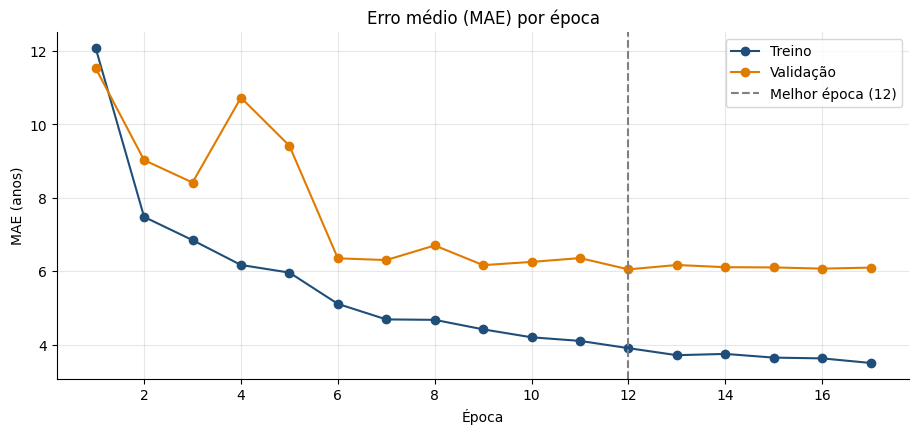

Melhor época: 12 | MAE treino: 3.90 | MAE validação: 6.05


In [9]:
hist = pd.DataFrame(historico.history)
fig, ax = plt.subplots()
ax.plot(hist.index + 1, hist["mae"], marker="o", color=AZUL, label="Treino")
ax.plot(hist.index + 1, hist["val_mae"], marker="o", color=LARANJA, label="Validação")
melhor = hist["val_mae"].idxmin()
ax.axvline(melhor + 1, color="gray", ls="--", label=f"Melhor época ({melhor + 1})")
ax.set_title("Erro médio (MAE) por época")
ax.set_xlabel("Época")
ax.set_ylabel("MAE (anos)")
ax.legend()
plt.show()
print(f"Melhor época: {melhor + 1} | MAE treino: {hist['mae'][melhor]:.2f} | MAE validação: {hist['val_mae'][melhor]:.2f}")

### Conclusões

- O *early stopping* encerrou o treino na época 17 e recuperou o modelo da **época 12**, a de menor erro na validação.
- O erro ficou em **3,90 anos no treino e 6,05 na validação**. A diferença entre os dois caiu de 3,7 anos, na versão original, para **2,2 anos**: o overfitting diminuiu, embora ainda exista, o que é comum com poucas milhares de fotos.
- A redução automática da taxa de aprendizado ajudou o modelo a fazer ajustes finos nas últimas épocas.

[Voltar ao Índice](#back)

## Etapa 6. Avaliação no conjunto de teste <a id='evaluation'></a>

O conjunto de teste não foi usado em nenhum momento do treino. É a estimativa mais honesta de como o modelo se comportaria com clientes novos.

Para ter uma referência, comparo com uma **linha de base** que sempre "chuta" a idade média do treino.

In [10]:
idades_teste = dados.loc[dados["parte"] == "test", "real_age"].values
previsoes_teste = modelo.predict(ds_teste, verbose=0).ravel()

mae_teste = np.mean(np.abs(previsoes_teste - idades_teste))
media_treino = dados.loc[dados["parte"] == "train", "real_age"].mean()
mae_base = np.mean(np.abs(media_treino - idades_teste))

print(f"MAE no teste: {mae_teste:.2f} anos")
print(f"MAE da linha de base (sempre a idade média): {mae_base:.2f} anos")
print(f"Redução do erro em relação à linha de base: {1 - mae_teste / mae_base:.0%}")
print("MAE da versão anterior (Dense(12), medido na validação): 5,79 anos")

MAE no teste: 5.96 anos
MAE da linha de base (sempre a idade média): 13.29 anos
Redução do erro em relação à linha de base: 55%
MAE da versão anterior (Dense(12), medido na validação): 5,79 anos


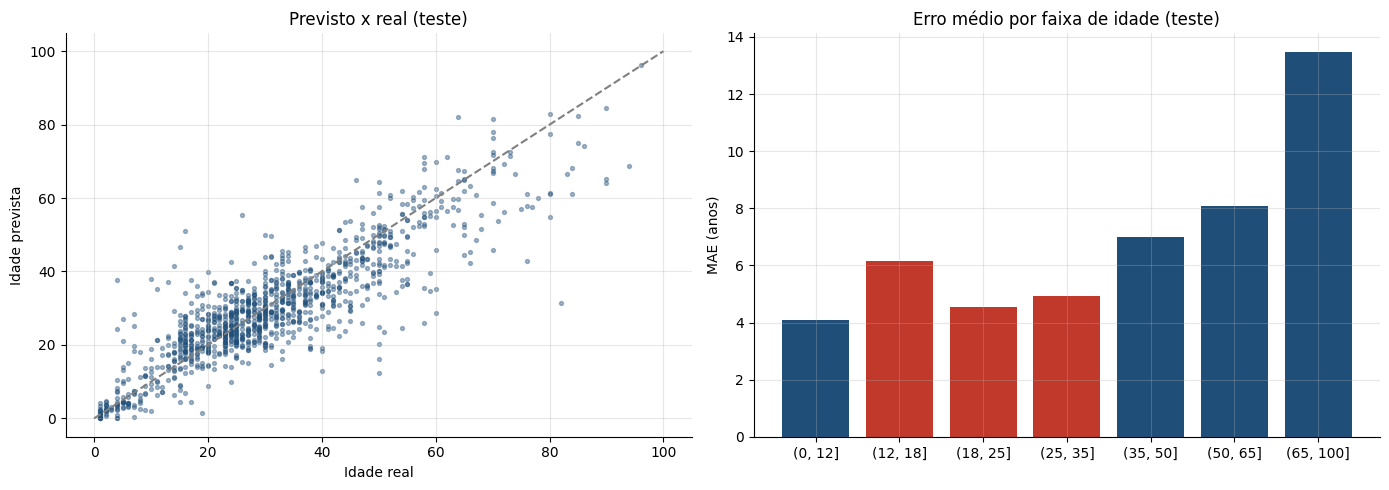

(0, 12]       4.08
(12, 18]      6.14
(18, 25]      4.54
(25, 35]      4.91
(35, 50]      6.99
(50, 65]      8.08
(65, 100]    13.47


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
axs[0].scatter(idades_teste, previsoes_teste, s=8, alpha=0.4, color=AZUL)
axs[0].plot([0, 100], [0, 100], color="gray", ls="--")
axs[0].set_xlabel("Idade real")
axs[0].set_ylabel("Idade prevista")
axs[0].set_title("Previsto x real (teste)")

faixas = pd.cut(idades_teste, [0, 12, 18, 25, 35, 50, 65, 100])
erro_faixa = pd.Series(np.abs(previsoes_teste - idades_teste)).groupby(faixas, observed=True).mean()
axs[1].bar(erro_faixa.index.astype(str), erro_faixa.values, color=[VERMELHO if "18" in str(f) or "25" in str(f) else AZUL for f in erro_faixa.index])
axs[1].set_title("Erro médio por faixa de idade (teste)")
axs[1].set_ylabel("MAE (anos)")
plt.tight_layout()
plt.show()
print(erro_faixa.round(2).to_string())

### Conclusões

- No conjunto de teste, que o modelo nunca viu, o erro médio é de **5,96 anos**, **55% menor** que o da linha de base que sempre chuta a idade média (13,29 anos).
- O número fica próximo do 5,79 da versão anterior, mas agora é uma medida **mais confiável**: antes, o erro foi medido no mesmo conjunto usado para acompanhar o treino; agora, em fotos totalmente novas.
- **O erro cresce com a idade:** cerca de 4 anos até os 12 anos e 4,5 anos entre 18 e 25, mas 13,5 anos acima dos 65, faixa com menos fotos e mais variação na aparência.
- Na faixa mais importante para o negócio, de **12 a 18 anos**, o erro médio é de **6,1 anos**, o que reforça que o modelo não pode decidir sozinho.

[Voltar ao Índice](#back)

## Etapa 7. Uso no negócio: quando pedir documento <a id='business'></a>

Com um erro médio de alguns anos, o modelo não deve decidir sozinho se a pessoa é maior de idade. O uso sensato é como **ferramenta de apoio**: quando a idade estimada estiver abaixo de um limite de segurança, o sistema avisa o caixa para **pedir um documento**.

Simulo vários limites e meço:
- **Menores identificados:** dos clientes com menos de 18 anos, quantos teriam o documento solicitado (o ideal é perto de 100%)
- **Adultos abordados:** dos clientes com 18 anos ou mais, quantos teriam o documento solicitado sem necessidade (o custo da política)

In [12]:
menores = idades_teste < 18
linhas = []
for limite in [18, 20, 22, 25, 28, 30]:
    pede_documento = previsoes_teste < limite
    linhas.append({
        "pedir documento se a idade estimada for menor que": limite,
        "menores identificados (%)": pede_documento[menores].mean() * 100,
        "adultos abordados (%)": pede_documento[~menores].mean() * 100,
    })
pd.DataFrame(linhas).round(1)

,pedir documento se a idade estimada for menor que,menores identificados (%),adultos abordados (%)
0,18,63.4,3.7
1,20,73.6,8.5
2,22,81.7,13.7
3,25,88.9,24.7
4,28,94.0,36.4
5,30,95.7,44.6


### Conclusões

- **Pedir documento quando a idade estimada for menor que 25 anos** identifica **89% dos menores**, abordando 25% dos adultos. A lógica é a mesma de políticas como a "Challenge 25", usada no varejo do Reino Unido: pedir documento a quem parece ter menos de 25 anos.
- Um limite de **28 anos** sobe a identificação de menores para 94%, mas passa a abordar 36% dos adultos.
- Como cerca de 1 em cada 10 menores ainda passaria despercebido no limite de 25 anos, o modelo deve **apoiar** o atendente, e não substituí-lo.

**Atenção à LGPD:** a foto do rosto usada para estimar a idade é um **dado biométrico**, classificado como dado pessoal sensível pela LGPD (Art. 5º, II). Antes de qualquer uso real, seria preciso definir a base legal, informar os clientes de forma clara e não armazenar as imagens além do necessário.

[Voltar ao Índice](#back)

## Conclusão geral <a id='end'></a>

Neste projeto, corrigi e refiz o modelo de estimativa de idade por foto, usando transfer learning com a ResNet50 em **7.591 fotos de rostos**.

**O que mudou em relação à primeira versão:**

- A camada de saída passou de `Dense(12)` para **`Dense(1)`**, o formato correto para prever um único número.
- A avaliação passou a ser feita em um **conjunto de teste** separado, que o modelo só viu no final.
- **Aumento de dados, dropout e early stopping** reduziram a diferença entre o erro de treino e o de validação de 3,7 para 2,2 anos.
- O pré-processamento passou a ser o **oficial da ResNet50**.

**Principais resultados:**

- **MAE de 5,96 anos no teste**, 55% menor que o de uma linha de base que sempre chuta a idade média.
- O erro é menor entre crianças e jovens adultos (cerca de 4 a 5 anos) e bem maior acima dos 65 anos (13,5 anos).
- Pedir documento quando a idade estimada for menor que **25 anos** identificaria **89% dos menores**, abordando 25% dos adultos.

**Recomendação:** usar o modelo como **apoio ao atendente**, com limite de 25 anos para pedir documento, e nunca como decisão automática. Qualquer uso real exige cuidados com a LGPD, porque a foto do rosto é um dado biométrico sensível.

**Próximos passos:**

- Coletar mais fotos de adolescentes, a faixa mais importante para o negócio, e de idosos, onde o erro é maior
- Testar arquiteturas mais recentes, como a EfficientNet
- Avaliar se o erro é parecido entre grupos de pessoas diferentes, para evitar que o modelo aborde mais um grupo do que outro

[Voltar ao Índice](#back)